<a href="https://colab.research.google.com/github/jayyadav-000/Mall-Customer-Segmentation-Dataset-Groceries-Market-Basket-Dataset/blob/main/ml_lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name Jay Yadav

Roll no BETN1AI25139

SEC E

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

In [49]:
df = pd.read_csv("https://raw.githubusercontent.com/jayyadav-000/Mall-Customer-Segmentation-Dataset-Groceries-Market-Basket-Dataset/main/Mall_Customers.csv")

In [50]:
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [51]:
df.tail(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
190,191,Female,34,103,23
191,192,Female,32,103,69
192,193,Male,33,113,8
193,194,Female,38,113,91
194,195,Female,47,120,16
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [52]:
df.shape

(200, 5)

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [54]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [55]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


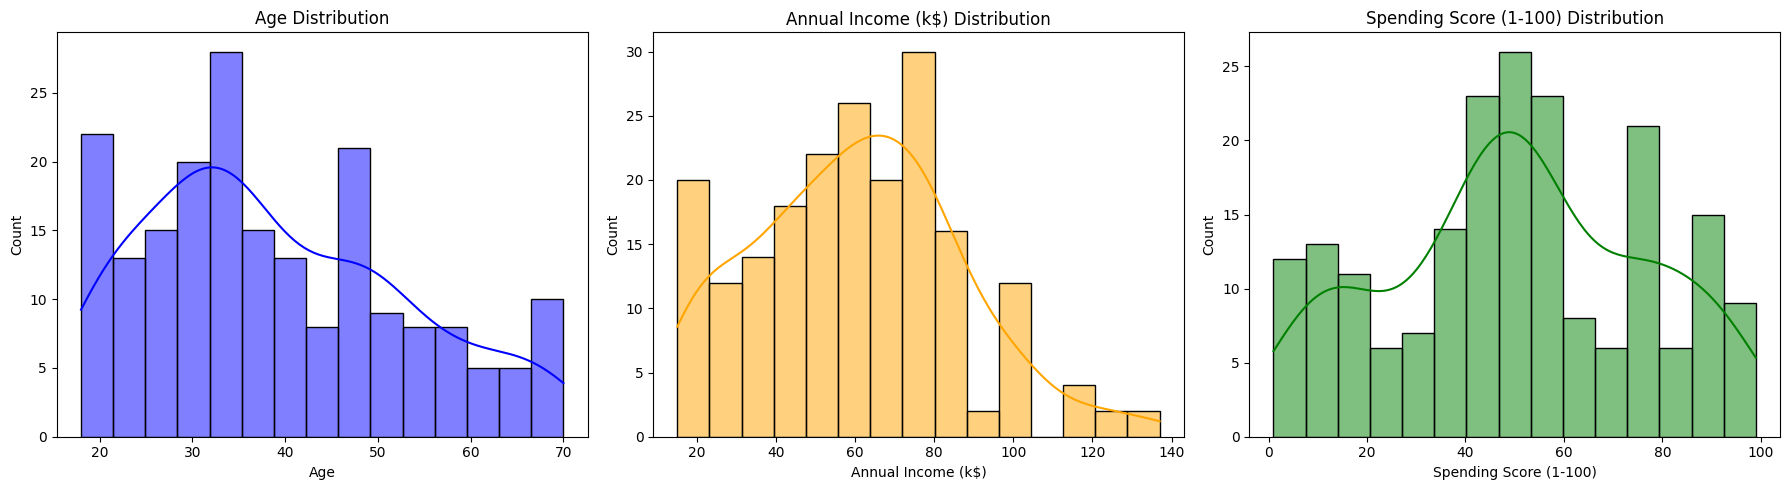

In [56]:
# Histogram
fig, axes = plt.subplots(1, 3, figsize = (18, 5))

sns.histplot(df['Age'], kde = True, bins = 15, color = 'blue', ax = axes[0])
axes[0].set_title('Age Distribution')

sns.histplot(df['Annual Income (k$)'], kde = True, bins = 15, color = 'orange', ax = axes[1])
axes[1].set_title('Annual Income (k$) Distribution')

sns.histplot(df['Spending Score (1-100)'], kde = True, bins = 15, color = 'green', ax = axes[2])
axes[2].set_title('Spending Score (1-100) Distribution')

plt.tight_layout()
plt.show()

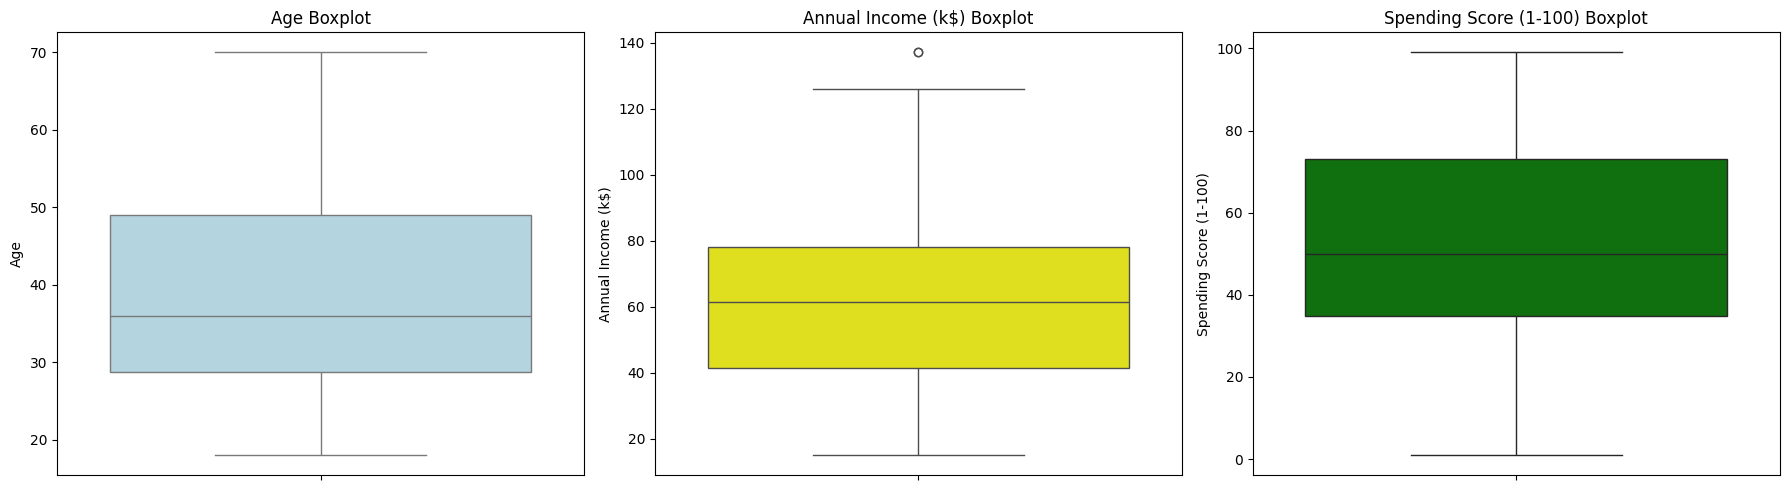

In [57]:
# Boxplot
fig, axes = plt.subplots(1, 3, figsize = (18, 5))

sns.boxplot(y = df['Age'], color = 'lightblue', ax = axes[0])
axes[0].set_title('Age Boxplot')

sns.boxplot(y = df['Annual Income (k$)'], color = 'yellow', ax = axes[1])
axes[1].set_title('Annual Income (k$) Boxplot')

sns.boxplot(y = df['Spending Score (1-100)'], color = 'green', ax = axes[2])
axes[2].set_title('Spending Score (1-100) Boxplot')

plt.tight_layout()
plt.show()

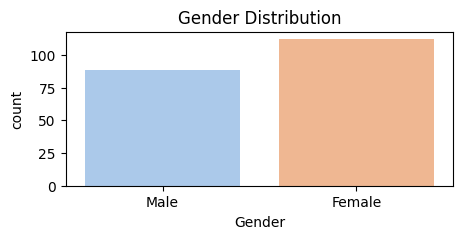

In [58]:
# Gender Count Plot
plt.figure(figsize = (5, 2))
sns.countplot(data = df, x = 'Gender', palette = 'pastel', hue = 'Gender', legend = False)
plt.title('Gender Distribution')
plt.show()

**TASK 2**

In [59]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [60]:
# Encoding gender column
X = df.drop(columns = ['CustomerID'])
X['Gender'] = X['Gender'].map({'Male': 0, 'Female': 1})

In [61]:
# Applying standard scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [62]:
# Converting it back to a dataframe
X_scaled_df = pd.DataFrame(X_scaled, columns = X.columns)
print("\nScaled Data Head:\n", X_scaled_df.head())


Scaled Data Head:
      Gender       Age  Annual Income (k$)  Spending Score (1-100)
0 -1.128152 -1.424569           -1.738999               -0.434801
1 -1.128152 -1.281035           -1.738999                1.195704
2  0.886405 -1.352802           -1.700830               -1.715913
3  0.886405 -1.137502           -1.700830                1.040418
4  0.886405 -0.563369           -1.662660               -0.395980


**task 3**

In [63]:
# K-Means clustering
X_cluster = X_scaled_df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Within-Cluster Sum of Squares
within_cluster = [KMeans(n_clusters = k, init = 'k-means++', random_state = 42, n_init = 10).fit(X_cluster).inertia_
    for k in range(1, 11)]

within_cluster

[399.99999999999994,
 269.69101219276405,
 157.70400815035939,
 108.92131661364358,
 65.56840815571681,
 55.057348270385965,
 44.86475569922555,
 37.22818767758587,
 32.39226763033118,
 29.981897788243703]

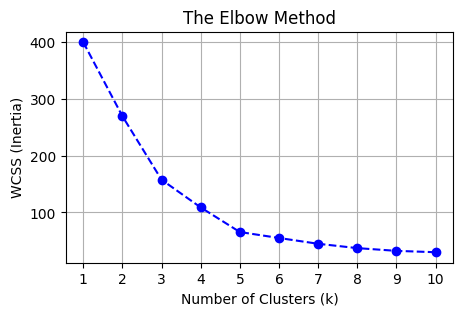

In [64]:
# Plotting Elbow curve
plt.figure(figsize = (5, 3))
plt.plot(range(1, 11), wcss, marker = 'o', linestyle = '--', color = 'b')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [65]:
kmeans = KMeans(n_clusters = 5, init = 'k-means++', random_state = 42, n_init = 10)
df['Cluster'] = kmeans.fit_predict(X_cluster)

**TASK 4**

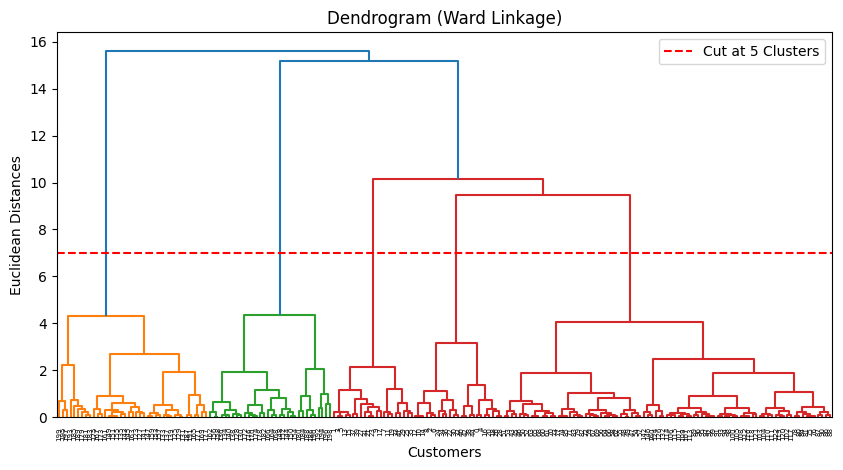

In [66]:
# Hierarchical clustering and dendogram plotting
plt.figure(figsize = (10, 5))
dendrogram = sch.dendrogram(sch.linkage(X_cluster, method = 'ward'))
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.axhline(y = 7, color = 'r', linestyle = '--', label = 'Cut at 5 Clusters')
plt.legend()
plt.show()

hc = AgglomerativeClustering(n_clusters = 5, metric = 'euclidean', linkage = 'ward')
df['HC_Cluster'] = hc.fit_predict(X_cluster)

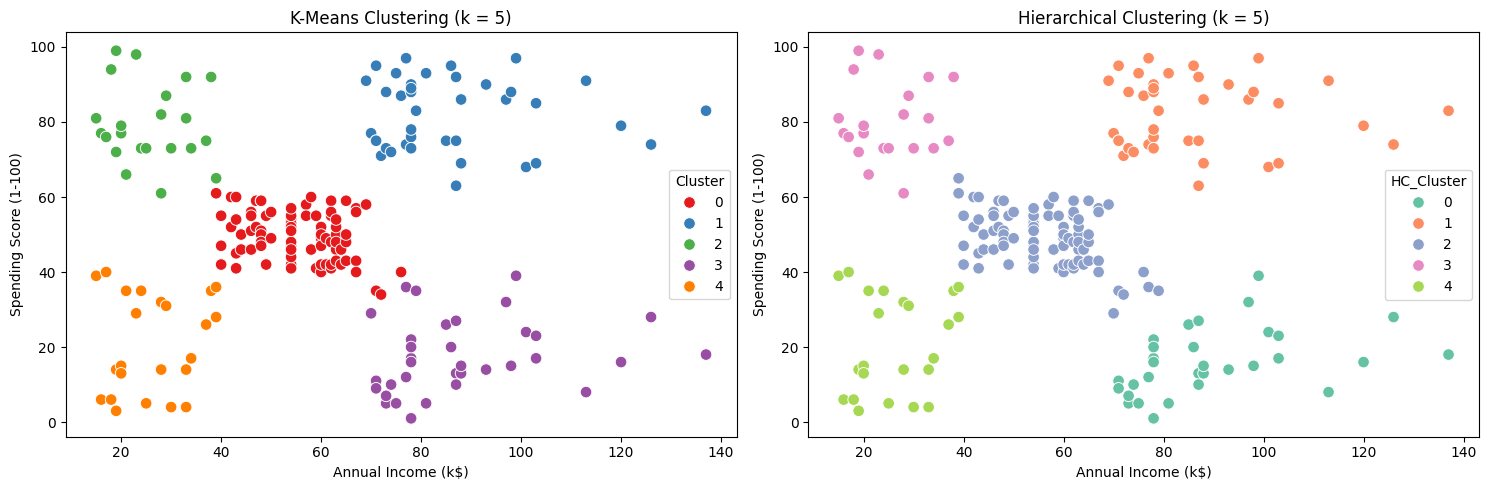

K-Means Silhouette Score:      0.5547
Hierarchical Silhouette Score: 0.5538


In [67]:
# Comparison
fig, axes = plt.subplots(1, 2, figsize = (15, 5))

# K-Means Plot
sns.scatterplot(data = df, x = 'Annual Income (k$)', y = 'Spending Score (1-100)',
    hue = 'Cluster', palette = 'Set1', s = 70, ax = axes[0])
axes[0].set_title('K-Means Clustering (k = 5)')

# Hierarchical Clustering Plot
sns.scatterplot(data = df, x = 'Annual Income (k$)', y = 'Spending Score (1-100)',
    hue = 'HC_Cluster', palette = 'Set2', s = 70, ax = axes[1])
axes[1].set_title('Hierarchical Clustering (k = 5)')

plt.tight_layout()
plt.show()

print(f"K-Means Silhouette Score:      {silhouette_score(X_cluster, df['Cluster']):.4f}")
print(f"Hierarchical Silhouette Score: {silhouette_score(X_cluster, df['HC_Cluster']):.4f}")

In [68]:
# DBSCAN
dbscan = DBSCAN(eps=0.35, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_cluster)

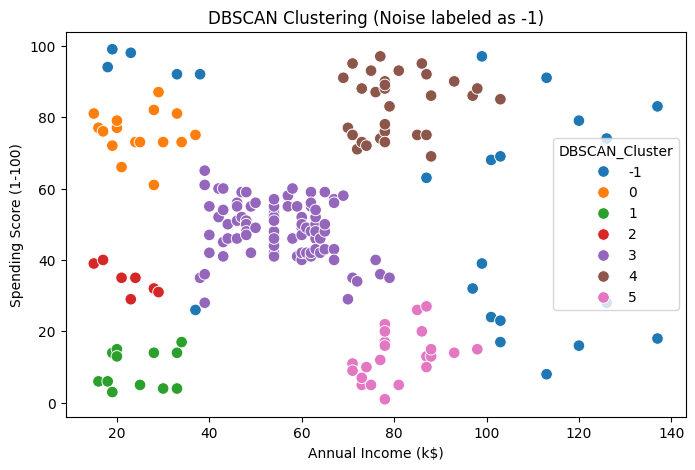

In [69]:
# Visualizing DBSCAN clusters
plt.figure(figsize = (8, 5))
sns.scatterplot(data = df, x = 'Annual Income (k$)', y = 'Spending Score (1-100)',
    hue = 'DBSCAN_Cluster', palette = 'tab10', s = 70)

plt.title('DBSCAN Clustering (Noise labeled as -1)')
plt.show()

In [70]:
print("DBSCAN Cluster Counts:\n", df['DBSCAN_Cluster'].value_counts())

DBSCAN Cluster Counts:
 DBSCAN_Cluster
 3    88
 4    31
-1    23
 5    23
 0    16
 1    12
 2     7
Name: count, dtype: int64


In [71]:
# DBSCAN performance
valid_mask = df['DBSCAN_Cluster'] != -1
db_score = silhouette_score(X_cluster[valid_mask], df.loc[valid_mask, 'DBSCAN_Cluster'])
print(f"DBSCAN Silhouette Score (excluding noise): {db_score:.4f}")

DBSCAN Silhouette Score (excluding noise): 0.5577


In [72]:
from google.colab import files
cleaned_df = df.copy()

In [73]:
cleaned_df.to_csv("cleaned_Mall_Customers.csv", index = False)
files.download("cleaned_Mall_Customers.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**TASK 5**

In [74]:
df1 = pd.read_csv("https://raw.githubusercontent.com/jayyadav-000/Mall-Customer-Segmentation-Dataset-Groceries-Market-Basket-Dataset/main/Groceries_dataset.csv")

In [75]:
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [76]:
warnings.filterwarnings("ignore", category = DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [77]:
df1.head(10)

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
5,4941,14-02-2015,rolls/buns
6,4501,08-05-2015,other vegetables
7,3803,23-12-2015,pot plants
8,2762,20-03-2015,whole milk
9,4119,12-02-2015,tropical fruit


In [78]:
# Grouping
baskets = df1.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).tolist()

In [79]:
# One-hot encoding
te = TransactionEncoder()
te_ary = te.fit(baskets).transform(baskets)
basket_df = pd.DataFrame(te_ary, columns = te.columns_)

print(f"\nTotal Transactions: {basket_df.shape[0]}, Unique Items: {basket_df.shape[1]}")


Total Transactions: 14963, Unique Items: 167


In [80]:
min_sup = 0.001
min_conf = 0.1

# Apriori Algorithm
start_apriori = time.perf_counter()
freq_items_apriori = apriori(basket_df, min_support = min_sup, use_colnames = True)
rules_apriori = association_rules(freq_items_apriori, metric = "confidence", min_threshold = min_conf)
time_apriori = time.perf_counter() - start_apriori

# FP-Growth Algorithm
start_fpgrowth = time.perf_counter()
freq_items_fp = fpgrowth(basket_df, min_support = min_sup, use_colnames = True)
rules_fp = association_rules(freq_items_fp, metric = "confidence", min_threshold = min_conf)
time_fp = time.perf_counter() - start_fpgrowth

# Sort rules by Lift descending for inspection
rules_apriori = rules_apriori.sort_values(by = 'lift', ascending = False).reset_index(drop = True)
rules_fp = rules_fp.sort_values(by = 'lift', ascending = False).reset_index(drop = True)

print("Top 5 Association Rules (Sorted by Lift):")
print(rules_fp[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(5))

Top 5 Association Rules (Sorted by Lift):
             antecedents        consequents   support  confidence      lift
0   (yogurt, whole milk)          (sausage)  0.001470    0.131737  2.182917
1  (sausage, whole milk)           (yogurt)  0.001470    0.164179  1.911760
2      (sausage, yogurt)       (whole milk)  0.001470    0.255814  1.619866
3                (flour)   (tropical fruit)  0.001069    0.109589  1.617141
4     (processed cheese)  (root vegetables)  0.001069    0.105263  1.513019


In [81]:
# Comparison
comparison_df = pd.DataFrame({
    'Metric': ['Execution Time (seconds)',
                'Frequent Itemsets Found',
                'Association Rules Generated',
                'Mean Support', 'Max Support',
                'Mean Confidence', 'Max Confidence',
                'Mean Lift', 'Max Lift'],
    'Apriori': [round(time_apriori, 4),
                len(freq_items_apriori),
                len(rules_apriori),
                round(rules_apriori['support'].mean(), 5),
                round(rules_apriori['support'].max(), 5),
                round(rules_apriori['confidence'].mean(), 4),
                round(rules_apriori['confidence'].max(), 4),
                round(rules_apriori['lift'].mean(), 4),
                round(rules_apriori['lift'].max(), 4)],
    'FP-Growth': [round(time_fp, 4),
                  len(freq_items_fp),
                  len(rules_fp),
                  round(rules_fp['support'].mean(), 5),
                  round(rules_fp['support'].max(), 5),
                  round(rules_fp['confidence'].mean(), 4),
                  round(rules_fp['confidence'].max(), 4),
                  round(rules_fp['lift'].mean(), 4),
                  round(rules_fp['lift'].max(), 4)]})

print(comparison_df.to_string(index = False))

                     Metric   Apriori  FP-Growth
   Execution Time (seconds)   3.08550   32.05460
    Frequent Itemsets Found 750.00000  750.00000
Association Rules Generated 130.00000  130.00000
               Mean Support   0.00294    0.00294
                Max Support   0.01484    0.01484
            Mean Confidence   0.12590    0.12590
             Max Confidence   0.25580    0.25580
                  Mean Lift   0.94740    0.94740
                   Max Lift   2.18290    2.18290


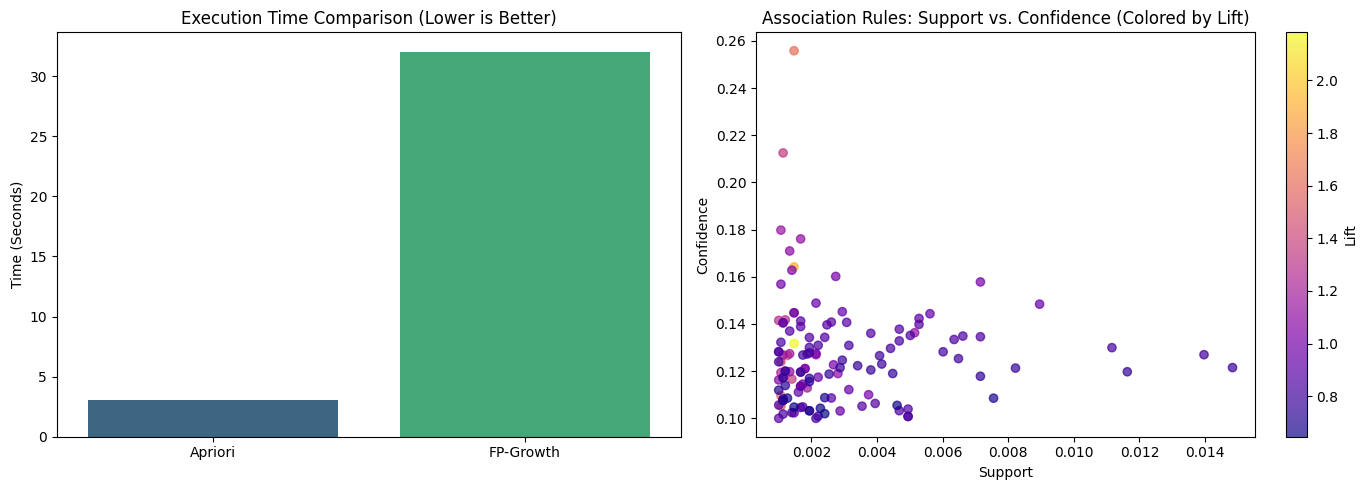

In [82]:
# Visualization of Execution Time & Top Rules
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

# Execution Time Bar Plot
sns.barplot(x = ['Apriori', 'FP-Growth'], y = [time_apriori, time_fp], palette = 'viridis',
            hue = ['Apriori', 'FP-Growth'], legend = False, ax = axes[0])
axes[0].set_title('Execution Time Comparison (Lower is Better)')
axes[0].set_ylabel('Time (Seconds)')

# Support vs Confidence colored by Lift
scatter = axes[1].scatter(rules_fp['support'], rules_fp['confidence'],
                          c = rules_fp['lift'], cmap = 'plasma', alpha = 0.7)
plt.colorbar(scatter, ax = axes[1], label = 'Lift')
axes[1].set_title('Association Rules: Support vs. Confidence (Colored by Lift)')
axes[1].set_xlabel('Support')
axes[1].set_ylabel('Confidence')

plt.tight_layout()
plt.show()

In [83]:
from google.colab import files
cleaned_df1 = df.copy()

In [86]:
cleaned_df1.to_csv("cleaned_Groceries_dataset.csv", index = False)
files.download("cleaned_Groceries_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Summary

Identical Rule Output (Exactness): Both Apriori and FP-Growth are exact frequent itemset mining algorithms. Given identical min_support and min_confidence thresholds, both produce the exact same frequent itemsets, rule counts, and Support, Confidence, and Lift values.

Execution Speed & Scalability: FP-Growth is significantly faster than Apriori, especially as min_support decreases.

Behavior of Metrics on Grocery Data:

1. Support remains low across multi-item rules (often 0.001 - 0.005) due to the high dimensionality of retail inventory (~167 unique items).

2. Confidence tends to skew toward high-frequency staples (e.g., whole milk, rolls/buns) appearing as consequents simply because they appear in a large share of all baskets.

3. Lift (>1) provides the clearest signal of true product affinity by controlling for the baseline popularity of the consequent item.